# 02 – Geometrická a fázová analýza: Trajektorie na Poincarého sféře a Takensova 3D rekonstrukce
Výpočet geodetické úhlové rychlosti $\Delta\theta_t = \arccos(\vec{s}(t)\cdot\vec{s}(t-\tau))$, integrálu délky dráhy na sféře po Savitzky-Golayově filtraci s dead-zone prahem a invariantů Takensova 3D zpožděného atraktoru $[x(t), x(t+\tau), x(t+2\tau)]$.

Metriky separability (Poincaré & Takens): {'method_name': 'poincare', 'fdr_score': 0.2551, 'silhouette_score': -0.1713, 'davies_bouldin_score': 12.2254, 'mutual_info_mean': 0.3349, 'anova_f_mean': 268.9101, 'separability_by_phenomenon': {'static_load_fdr': 0.101, 'thermal_fdr': 0.249, 'transition_edge_fdr': 0.0002}}


,measurement_code,inherited_label,poincare_geodesic_length,poincare_vel_max,takens_radius_mean
0,0773,klid_pred_teplotou,0.029517,0.000592,0.000200
1,0773,klid_pred_teplotou,0.027973,0.000670,0.000220
2,0773,klid_pred_teplotou,0.029996,0.000543,0.000234
3,0773,klid_pred_teplotou,0.030446,0.000609,0.000306
4,0773,klid_pred_teplotou,0.035250,0.002922,0.000323
5,0773,klid_pred_teplotou,0.030695,0.001741,0.000272
6,0773,klid_pred_teplotou,0.023885,0.000533,0.000231
7,0773,klid_pred_teplotou,0.024188,0.000535,0.000281
8,0773,klid_pred_teplotou,0.028316,0.000588,0.000265
9,0773,klid_pred_teplotou,0.029794,0.000592,0.000312


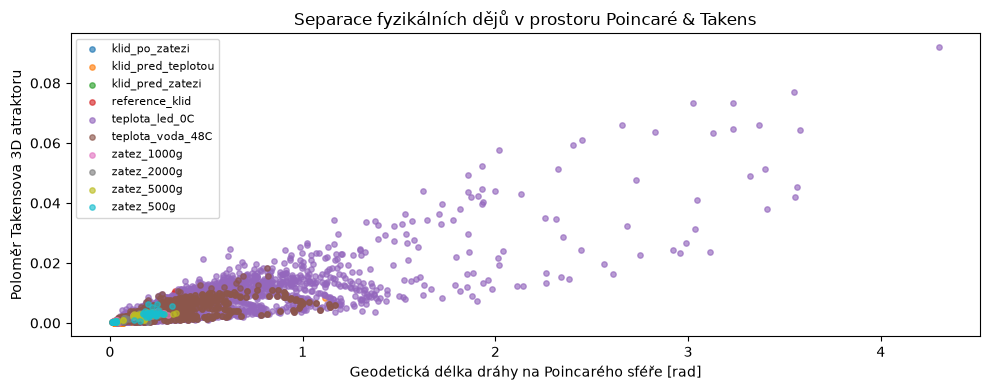

In [1]:
import matplotlib.pyplot as plt
from icaros.analysis.runner import load_windows_with_signals, run_single_silver_method
from icaros.db.s3 import read_parquet_from_s3

df_win, signals, fs = load_windows_with_signals("win128_stride32")
res = run_single_silver_method("poincare", df_win, signals, fs, "win128_stride32")
print("Metriky separability (Poincaré & Takens):", {k: v for k, v in res.items() if k != "s3_uri"})
df_p = read_parquet_from_s3(res["s3_uri"])
display(df_p[["measurement_code", "inherited_label", "poincare_geodesic_length", "poincare_vel_max", "takens_radius_mean"]].head(12))

fig, ax = plt.subplots(figsize=(10, 4))
for lbl, grp in df_p.groupby("inherited_label"):
    ax.scatter(grp["poincare_geodesic_length"], grp["takens_radius_mean"], s=15, alpha=0.65, label=lbl)
ax.set_xlabel("Geodetická délka dráhy na Poincarého sféře [rad]")
ax.set_ylabel("Poloměr Takensova 3D atraktoru")
ax.set_title("Separace fyzikálních dějů v prostoru Poincaré & Takens")
ax.legend(fontsize=8, loc="best")
plt.tight_layout()
plt.show()